# A stepping loop in `lax.scan`

256 balls fly until they land. The kernel decides who has landed and says so in a mask; `lax.scan` carries the mask
to the next step, so a landed ball is never touched again.

**Time:** ~5 min · **Runs on:** CPU, GPU if visible (picked up automatically) · **You need:** eagle, hawk and JAX

You will build: a scan that stops each ball where it lands, the same loop on the CPU and the GPU with identical
numbers, and a gradient through the whole loop.

**Colab or Kaggle:** run this first cell (it installs the packages and downloads the helper files this notebook uses). Elsewhere it only checks the imports.

In [1]:
# Colab setup, generated by python -m raptor_docs.nb colab_setup (do not edit).
import os

try:
    import google.colab  # noqa: F401
    HOSTED = True  # a Colab runtime
except ImportError:
    HOSTED = "KAGGLE_KERNEL_RUN_TYPE" in os.environ  # a Kaggle kernel

if HOSTED:
    import importlib.metadata, pathlib, re, shutil, subprocess, sys, urllib.request

    gpu = bool(shutil.which("nvidia-smi")) and subprocess.run(["nvidia-smi", "-L"], capture_output=True).returncode == 0
    extra = ""
    if gpu:
        # the CUDA major the runtime already has: a CuPy that is installed, else torch's, else the driver's
        major = None
        for m in ("13", "12"):
            try:
                importlib.metadata.version(f"cupy-cuda{m}x")
                major = m
                break
            except importlib.metadata.PackageNotFoundError:
                pass
        if major is None:
            try:
                import torch
                major = "13" if str(torch.version.cuda).startswith("13") else None
            except ImportError:
                pass
        if major is None:
            smi = re.search(r"CUDA Version: (\d+)", subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
            major = "13" if smi and int(smi.group(1)) >= 13 else "12"
        extra = f"[cuda{major}]"
        print(f"GPU found: installing the {extra} extras to match this runtime.")
    pre = ["--pre"] if os.environ.get("RAPTOR_PRE") else []  # optional: test a release candidate
    ref = os.environ.get("RAPTOR_REF", "main")  # optional: fetch the helper files from this git ref
    if pre or "RAPTOR_REF" in os.environ:
        print(f"Pre-release test: installing with --pre, helper files from {ref}.")
    # our packages with --upgrade, so a runtime that kept an older release gets the current one
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", *pre, f"raptor-eagle{extra}", f"raptor-hawk{extra}"])
    from packaging.version import Version

    try:
        old = Version(importlib.metadata.version("jax")) < Version("0.11.2")
    except importlib.metadata.PackageNotFoundError:
        old = True
    if old:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", f"jax{extra}>=0.11.2"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "matplotlib"])
    base = os.environ.get("RAPTOR_RAW_BASE", "https://raw.githubusercontent.com")  # optional: a local mirror
    top = os.environ.get("RAPTOR_WORKDIR") or ("/kaggle/working" if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "/content")
    root = pathlib.Path(top) / "eagle"
    for rel in (
        "docs/content/_shared/nb_helpers.py",
        "docs/content/_shared/themed_figure.py",
    ):
        (root / rel).parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"{base}/amasat01/eagle/{ref}/{rel}", root / rel)
    (root / "docs/content/userguide/tutorials").mkdir(parents=True, exist_ok=True)
    os.chdir(root / "docs/content/userguide/tutorials")
    if not gpu:
        print("Running on the CPU (no GPU in this runtime). For a GPU: " + ("Settings → Accelerator → GPU T4 x2." if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "Runtime → Change runtime type → T4 GPU."))

try:
    import eagle, hawk, matplotlib  # noqa: F401
except ImportError as err:
    raise ImportError(
        "eagle, hawk, matplotlib not found. Install with `pip install matplotlib raptor-eagle raptor-hawk`. For a GPU, add [cuda12] (or [cuda13]) to raptor-eagle and raptor-hawk."
    ) from err

In [2]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent.parent / "_shared"))
from nb_helpers import plot_style
plot_style()

## A kernel that finishes its own samples

`terminated = r_next[2] < 0.0` marks a ball as landed. The bridge returns that mask as the last output; hand it back
in at the next step and the kernel skips every finished ball.

In [3]:
import os

os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")  # leave GPU memory for your other libraries
import jax
import jax.numpy as jnp

jax.config.update("jax_enable_x64", True)  # the kernel runs in float64

import hawk
from hawk import Mutable, Param, Terminated, Vector
from hawk.math import norm, vec

from eagle.frameworks import jax as eagle_jax


@hawk.kernel(steps=1)
def flight(r: Vector[3], v: Vector[3], cd: Param, dt: Param, g: Param, terminated: Terminated,
           r_next: Mutable[Vector[3]], v_next: Mutable[Vector[3]]):
    a = vec(0.0, 0.0, -g) - cd * norm(v) * v
    v_new = v + dt * a
    v_next = v_new
    r_next = r + dt * v_new
    terminated = r_next[2] < 0.0

step = eagle_jax.function(flight, wrt=("r", "v", "cd"))
step

KernelFunction('flight', inputs=['r', 'v', 'cd', 'dt', 'g', 'terminated'], outputs=['r_next', 'v_next', 'terminated'], wrt=['r', 'v', 'cd'])

## Scan the flight

A finished ball's outputs are zero (the kernel did not write them), so `jnp.where` keeps its last position. The scan
returns every position along the way and how many balls have landed after each step.

In [4]:
N, STEPS, DT, G, CD = 256, 360, 0.02, 9.81, 0.004
k = jax.random.split(jax.random.key(0), 3)
speed = 20 + 20 * jax.random.uniform(k[0], (N,))
elevation = jnp.radians(20) + jnp.radians(50) * jax.random.uniform(k[1], (N,))
heading = 2 * jnp.pi * jax.random.uniform(k[2], (N,))
v0 = jnp.stack([speed * jnp.cos(elevation) * jnp.cos(heading),
                speed * jnp.cos(elevation) * jnp.sin(heading),
                speed * jnp.sin(elevation)])
r0 = jnp.zeros((3, N)).at[2].set(1.0)


def body(carry, _, cd=CD):
    r, v, landed = carry
    r_next, v_next, landed_next = step(r, v, cd, DT, G, landed)
    r_next, v_next = jnp.where(landed, r, r_next), jnp.where(landed, v, v_next)
    return (r_next, v_next, landed_next), (r_next, landed_next.sum())


@jax.jit
def fly(r, v, landed):
    return jax.lax.scan(body, (r, v, landed), None, length=STEPS)


(r, v, landed), (path, count) = fly(r0, v0, jnp.zeros(N, dtype=bool))
print("landed after", STEPS, "steps:", int(landed.sum()), "of", N)
print("landed after every 60th step:", count[59::60].tolist())

landed after 360 steps: 256 of 256
landed after every 60th step: [0, 27, 96, 190, 247, 256]


Left, the paths of 12 balls, each frozen where it landed; right, how many balls have landed as the flight goes on.


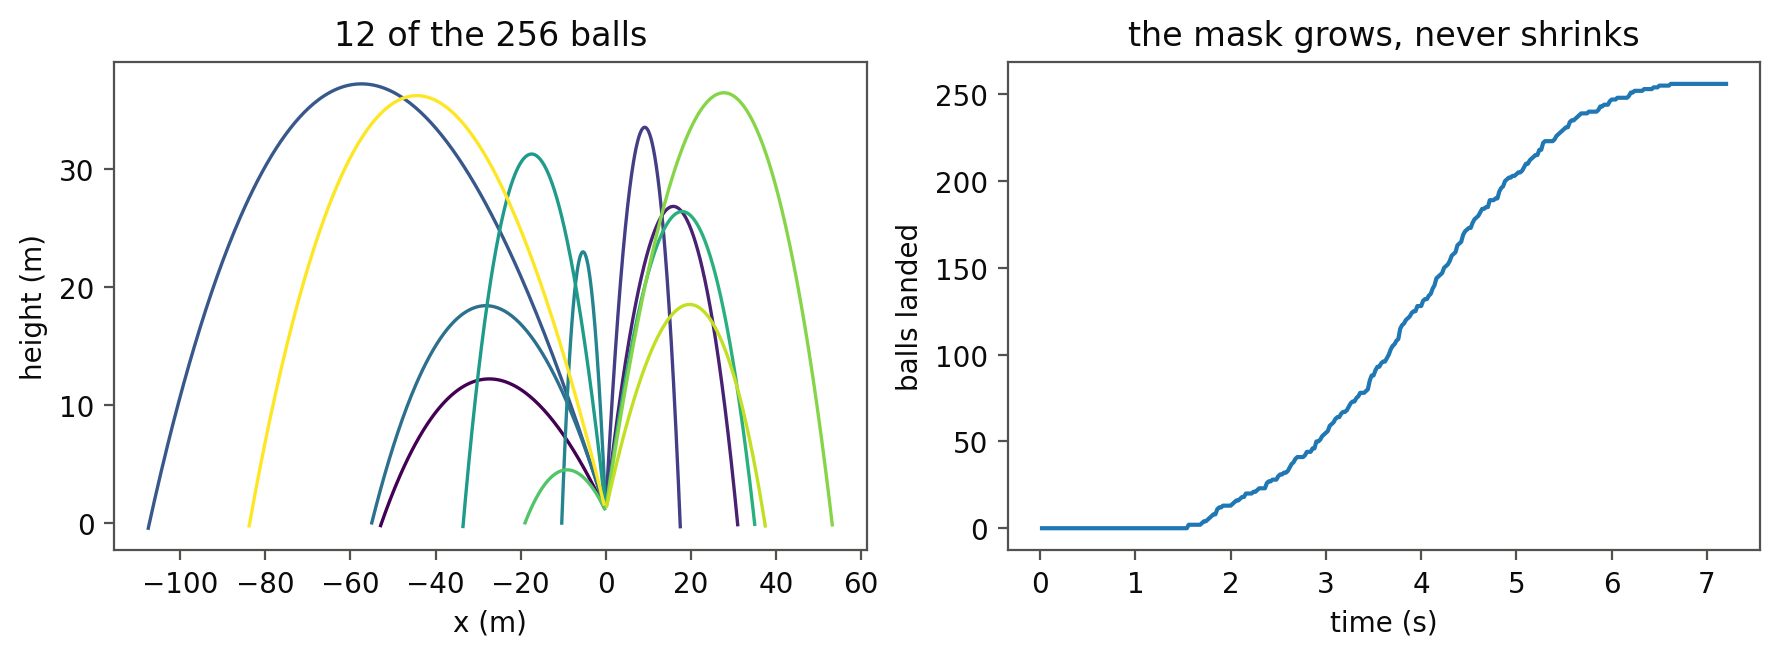
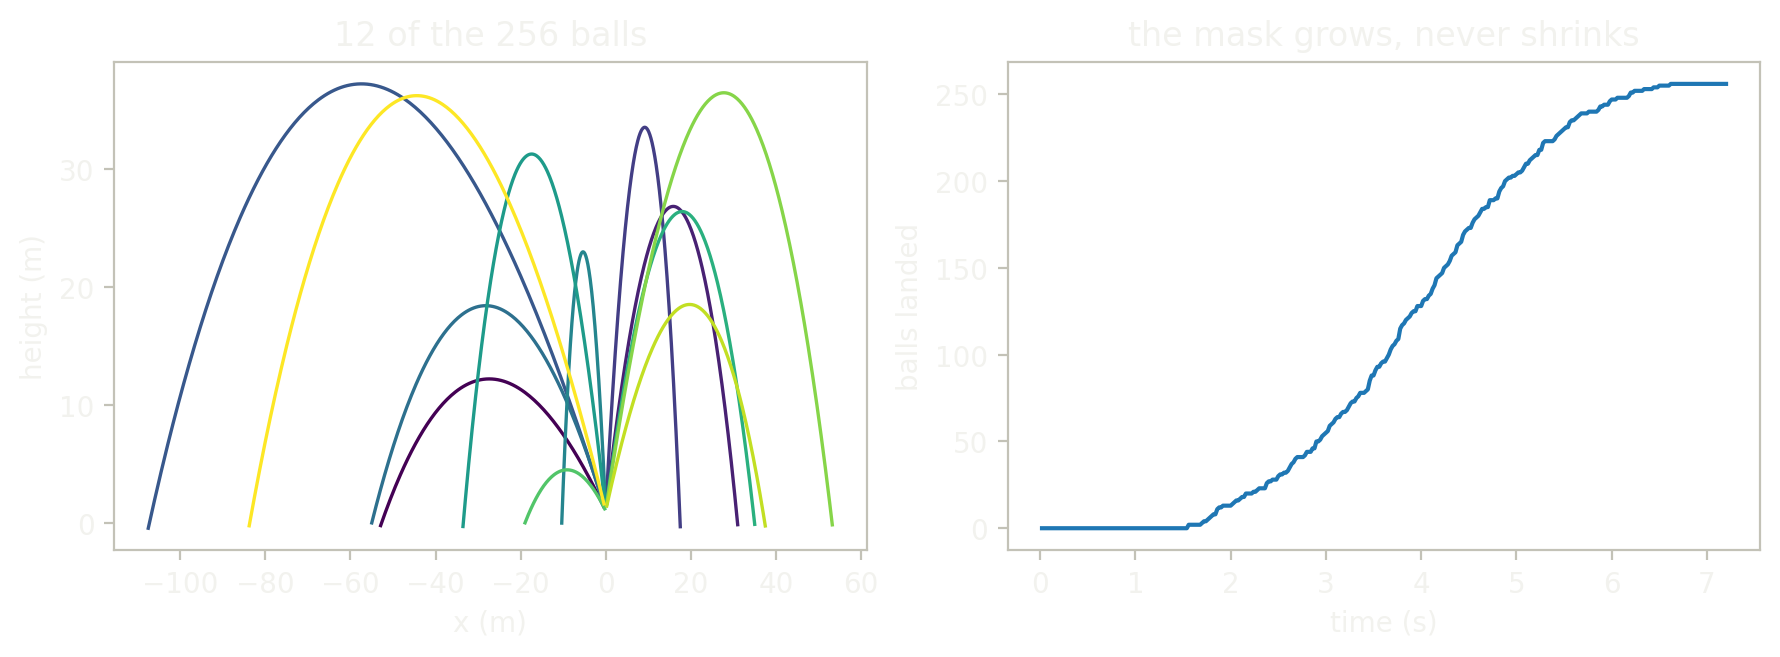

In [5]:
import matplotlib.pyplot as plt
from themed_figure import show

fig, (ax, bx) = plt.subplots(1, 2, figsize=(9, 3.4))
for i, colour in zip(range(12), plt.cm.viridis([j / 11 for j in range(12)])):
    ax.plot(path[:, 0, i], path[:, 2, i], color=colour, lw=1.2)
ax.set(xlabel="x (m)", ylabel="height (m)", title="12 of the 256 balls")
bx.plot(jnp.arange(1, STEPS + 1) * DT, count)
bx.set(xlabel="time (s)", ylabel="balls landed", title="the mask grows, never shrinks")
plt.tight_layout()
show()

## The same loop on every platform

The kernel runs inline on the CPU and on XLA's stream on a GPU. Put the inputs on each device JAX has and compare:
the numbers match.

In [6]:
results = {}
for platform in ("cpu", "gpu"):
    try:
        device = jax.devices(platform)[0]
    except RuntimeError:
        continue  # this JAX has no such device
    inputs = [jax.device_put(x, device) for x in (r0, v0, jnp.zeros(N, dtype=bool))]
    (r_p, _, landed_p), _ = fly(*inputs)
    results[platform] = (int(landed_p.sum()), float(jnp.hypot(r_p[0], r_p[1]).mean()))
    print(f"{platform}: {results[platform][0]} landed, mean range {results[platform][1]:.6f} m")
if len(results) == 2:
    assert results["cpu"][0] == results["gpu"][0] and abs(results["cpu"][1] - results["gpu"][1]) < 1e-9
    print("identical on both")

cpu: 256 landed, mean range 67.477918 m


## Donate the mask

Calling the stepping function from your own loop instead of a scan? Pass the old mask with `donate_argnums` and the
kernel updates it in place: the returned mask is the same buffer.

In [7]:
one_step = jax.jit(lambda r, v, landed: step(r, v, CD, DT, G, landed), donate_argnums=2)
mask = jnp.zeros(N, dtype=bool)
pointer = mask.unsafe_buffer_pointer()
_, _, mask_next = one_step(r0, v0, mask)
print("same buffer:", mask_next.unsafe_buffer_pointer() == pointer, "| the old handle is spent:", mask.is_deleted())

same buffer: True | the old handle is spent: True


## Or hand the arrays to `until_done`

Outside `jit`, `eagle.until_done` runs the whole flight in one call and stops when the last ball has landed. It
takes your JAX arrays as they are: it reads them in place, runs on the side they are on, and never writes them.
Ask `Runner.result` for the answer, a new JAX array.

In [8]:
import eagle
import eagle.plan as eplan
from hawk import Scalar


@hawk.kernel(steps=1)
def drop(dt: Param, terminated: Terminated, h: Mutable[Scalar], v: Mutable[Scalar]):
    v = v - 9.81 * dt
    h = h + dt * v
    terminated = h < 0.0


heights = jnp.linspace(1.0, 50.0, N)
runner = eagle.until_done(eplan.auto(drop), max_steps=2000, h=heights, v=jnp.zeros(N), dt=0.01)
report = runner.run()
landed_at = runner.result("h")
print("done:", report.done, "| finished:", report.finished, "of", N, "| steps:", report.steps)
print("result is a", type(landed_at).__name__, "| your array is untouched:", bool((heights == jnp.linspace(1.0, 50.0, N)).all()))

done: True | finished: 256 of 256 | steps: 319


result is a ArrayImpl | your array is untouched: True


## A gradient through the whole loop

How far do the balls travel, and how does that change with drag? `grad` runs backward through all 360 steps and
through the mask: a landed ball contributes nothing after it lands. The landing step is a switch, so this is the
slope with each ball's landing step held fixed.

In [9]:
def mean_range(cd):
    (r, _, _), _ = jax.lax.scan(lambda c, _: body(c, _, cd), (r0, v0, jnp.zeros(N, dtype=bool)), None, length=STEPS)
    return jnp.hypot(r[0], r[1]).mean()


range_m, slope = jax.jit(jax.value_and_grad(mean_range))(CD)
print(f"mean range {float(range_m):.3f} m; d range / d cd = {float(slope):.1f} m")

mean range 67.478 m; d range / d cd = -2759.4 m


## What just happened

- The kernel finished the balls; the mask rode through `scan` as an ordinary carry.
- Eager, `jit`, `scan` and a donated mask all take the same path, on the CPU and the GPU.
- `until_done` takes the same JAX arrays and hands the answer back as a new one.
- `grad` went backward through every step, stopping at each landing.

## Limits

- <!-- limit: until-done-read-only --> `until_done` never writes a JAX or torch array (our design: your arrays stay yours): take the answer from `Runner.result(name)`, a new array of your framework. A NumPy or CuPy plane is still written in place.
- <!-- limit: until-done-mixed-planes --> `until_done` refuses a host plane beside a device plane, by name (our scope): move one side, so that every plane is on the host or every plane is on the device.

## Next

- [eagle inside your JAX program](../../interop/use_eagle_with_jax): what crosses, what is refused, the limits.
- [Gradients through a graph](10_gradients_through_a_graph): the same idea for a multi-kernel step in eagle itself.